<div style="padding: 18px 22px; border-radius: 12px; background: linear-gradient(110deg, #12304a, #187b8f); color: white; margin-bottom: 16px;">
  <div style="font-size: 0.78em; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.85;">HydroMT-SFINCS | Jakarta 01</div>
  <h1 style="color: white; margin: 8px 0 4px;">Build a SFINCS quadtree model from Python: Jakarta Bay 2026</h1>
  <div style="opacity: 0.95;">Wider Jakarta Bay domain with the 2026 reclamation bathymetry, FES2022b tide and STOFS surge at the boundary.</div>
</div>


In this notebook a **SFINCS** quadtree model is made using the underlying Python functions of **HydroMT-SFINCS**, following the official example [1b_build_quadtree_from_script](https://deltares.github.io/hydromt_sfincs/latest/_examples/1b_build_quadtree_from_script.html) step by step.

The model is situated in **Jakarta Bay** (Teluk Jakarta) and the **Thousand Islands** (Kepulauan Seribu). It is the most accurate set-up of all runs in `F:\asemelehoy` for the water level at the coast (see `BACA_DULU.txt`): the wide domain, the 2026 reclamation and harbour bathymetry, FES2022b tide plus STOFS surge at the open boundary, and no tide multiplier.

In [1]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"  # [JAKARTA] cegah error HDF5 saat file dibuka bersamaan
import geopandas as gpd
from pathlib import Path
from datetime import datetime
from shapely.geometry import box  # [JAKARTA]

from hydromt_sfincs import SfincsModel
from hydromt import log

MSL = 1.12  # [JAKARTA] MSL Sunda Kelapa dalam m EGM2008

C:\Users\ASUS\miniconda3\envs\asemelehoy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


This notebook builds a SFINCS model containing elevation data and spatially varying roughness (together processed into subgrid tables), and adds water level boundary conditions.

All datasets come from our own data catalog `../data/data_catalog.yml`: every raster has its own folder with a `.vrt` file, as in the old example `F:\sfincs_jakarta\data`.

<div style="padding: 14px 18px; border-left: 4px solid #187b8f; background: #eaf6f8; border-radius: 6px; margin: 12px 1em 12px 0; width: calc(100% - 1em); box-sizing: border-box; color: #111111;">
  <strong><span style="font-size: 1.15em; margin-right: 4px;">&#128161;</span> [JAKARTA] Note</strong>
  <p style="margin: 8px 0 0;">The official example uses the OpenStreetMap coastline (<code>osm_coastlines</code>) for the refinement. That dataset is not available for Jakarta, so we use the sea polygon from the Copernicus DEM (<code>laut_copdem</code>) in the same way. All vertical levels are in m EGM2008; MSL = +1.12 m EGM2008.</p>
</div>

**Steps followed in this notebook to build your SFINCS quadtree model:**
<ol start="0">
<li>Initialize the logger.</li><li>Initialize the SfincsModel class, data library and output folder.</li>
<li>Create a quadtree grid with coastline refinement.</li><li>Add elevation to the quadtree grid.</li>
<li>Create the active and inactive cell mask.</li><li>Add water-level and outflow boundaries.</li>
<li>Cut inactive cells from the quadtree grid.</li><li>Add spatially varying roughness.</li>
<li>Create quadtree subgrid-derived tables.</li><li>Add water-level time-series forcing.</li>
<li>Inspect the model and boundary conditions.</li><li>Write the model to disk.</li>
</ol>


Let's get started!

### 0. Initialize the logger


Initialize logging and choose the level of detail for the messages written to the notebook and log file.


In [2]:
model_root = "../model/jakarta_2026_tanpa_struktur"  # [JAKARTA]

# Initialize logging, the lower the log level number, the more verbose (more info) the output
# NOTSET=0-9, DEBUG=10, INFO=20, WARNING=30, ERROR=40, CRITICAL=50
log.initialize_logging()
log.set_log_level(log_level=20)

# Add file handler to log to a file
log_file = Path(model_root) / "hydromt_sfincs.log"
logger = log._add_filehandler(log_file)

2026-11-27 09:09:19,192 - hydromt - log - INFO - HydroMT version: 1.4.1


### 1. Initialize SfincsModel class, set data library and output folder:

Before we can use all the tools provided by HydroMT-SFINCS, we have to initialize the SfincsModel instance. This creates a shortcut to all the model components and methods to read, write and create these components. Furthermore, when initializing the model, we can specify which data catalog we use and where the model is/will be stored (the root).

In [3]:
# Initialize SfincsModel Python class with our Jakarta data catalog  # [JAKARTA]
sf = SfincsModel(
    data_libs=["../data/data_catalog.yml"],  # [JAKARTA] specify which data libraries to use
    root=model_root,  # specify the root directory for the model
    mode="w",  # specify the mode for opening the model (r=read only, r+=append, w=write,
    write_gis=True,  # specify whether to write GIS data
)

2026-11-27 09:09:19,206 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from ../data/data_catalog.yml
2026-11-27 09:09:19,511 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0).


### 2. Create a quadtree grid with coastline refinement

A quadtree grid starts at a base resolution and refines only selected areas. Every refinement level halves the cell size. [JAKARTA] The base cell is 800 m with five refinement levels: level 1 = 400 m (Jakarta Bay and the Thousand Islands), level 2 = 200 m (5 km around the inner bay), level 3 = 100 m (inner bay, the polygon `teluk_jakarta_coast.geojson`), level 4 = 50 m (400 m buffer around the coastline, as in the example) and level 5 = 25 m (Sunda Kelapa harbour basin, location of the SKLP tide gauge).

In [4]:
# first we obtain the region and the corresponding coastline (sea polygon)
region = {"geom": "../data/domain/domain_luas.geojson"}  # [JAKARTA]
gdf_region = sf.data_catalog.get_geodataframe(region["geom"]).to_crs("EPSG:4326")
gdf_laut = sf.data_catalog.get_geodataframe(
    "laut_copdem", bbox=tuple(gdf_region.total_bounds)  # [JAKARTA] pengganti osm_coastlines
)

# then we create a buffer around the coastline and prepare the refinement GeoDataFrame
gdf_laut_line = gdf_laut.to_crs("EPSG:32748").boundary
gdf_laut_buffer = gdf_laut_line.buffer(400)  # [JAKARTA] pita 400 m

# [JAKARTA] teluk dalam, Kep. Seribu dan kolam Sunda Kelapa untuk level lainnya
teluk = sf.data_catalog.get_geodataframe("../data/domain/teluk_jakarta_coast.geojson").to_crs("EPSG:32748").union_all()
seribu = gpd.GeoSeries([box(106.35, -6.1, 106.9, -5.4)], crs=4326).to_crs("EPSG:32748").iloc[0]
kolam = gpd.GeoSeries([box(106.795, -6.130, 106.825, -6.095)], crs=4326).to_crs("EPSG:32748").iloc[0]
pita = gpd.GeoSeries([gdf_laut_buffer.union_all().intersection(teluk.buffer(500))], crs="EPSG:32748").explode()
pita = pita[pita.area > 2e4].union_all()  # [JAKARTA] buang potongan kecil < 2 ha

gdf_refinement = gpd.GeoDataFrame(
    geometry=[teluk.buffer(15000).union(seribu), teluk.buffer(5000), teluk, pita, kolam], crs="EPSG:32748"
)
# assign the refinement level to each polygon
gdf_refinement["refinement_level"] = [1, 2, 3, 4, 5]
gdf_refinement["geometry"] = gdf_refinement.intersection(gdf_region.to_crs("EPSG:32748").union_all().buffer(1000))  # [JAKARTA]
gdf_refinement = gdf_refinement.explode(index_parts=False).reset_index(drop=True)  # [JAKARTA] quadtree hanya menerima Polygon, bukan MultiPolygon

2026-11-27 09:09:19,531 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading domain_luas.geojson GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\domain_luas.geojson
2026-11-27 09:09:19,611 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading laut_copdem GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\laut_copdem.geojson
2026-11-27 09:09:41,300 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading teluk_jakarta_coast.geojson GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\teluk_jakarta_coast.geojson


In [5]:
sf.quadtree_grid.create_from_region(
    region=region,
    res=800,  # [JAKARTA]
    rotated=True,
    crs=32748,  # [JAKARTA] UTM 48S
    refinement_polygons=gdf_refinement,
)

2026-11-27 09:09:41,381 - hydromt.data_catalog.data_catalog - data_catalog - WARNING - overwriting data source 'domain_luas.geojson' with provider user and version _UNSPECIFIED_.
2026-11-27 09:09:41,382 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading domain_luas.geojson GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\domain_luas.geojson
Refining ...
Time elapsed : 2.965141534805298 s
Finding neighbors ...
Time elapsed : 0.0326077938079834 s
Setting neighbors left and below ...
Time elapsed : 0.351959228515625 s
Getting uv points ...
Time elapsed : 0.2234354019165039 s
Making XUGrid ...
Got rid of duplicates in 0.8777 seconds
Made XUGrid in 0.0031 seconds


The resulting quadtree grid and refinement-level layer are available on the model.


<GeoAxes: title={'center': 'SFINCS level map'}, xlabel='x [m] - WGS 84 / UTM zone 48S', ylabel='y [m]'>

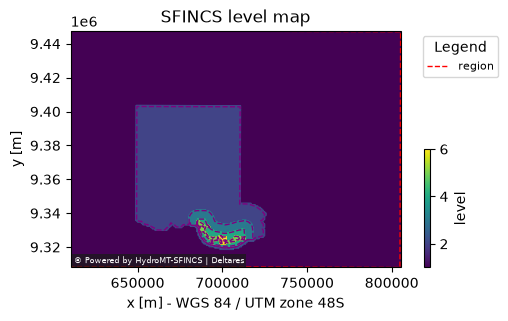

In [6]:
fig, ax = sf.plot_basemap(
    variable="level",
    plot_region=True,
    plot_bounds=False,
    bmap="sat",
    zoomlevel=9,  # [JAKARTA]
)
gdf_refinement.boundary.plot(ax=ax, color="purple", linewidth=1, linestyle="--")

### 3. Add elevation to the quadtree grid

Probably the most important datasets to create a proper SFINCS model are the digital elevation models (DEMs). However, often there are different datasets for describing the elevation on land, topography, and below water, bathymetry. HydroMT-SFINCS provides functionality to merge these different datasets onto the model grid.

2026-11-27 09:09:58,397 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading batimetri_reklamasi_2026 RasterDataset data from F:\asemelehoy\skema_terbaik\data\batimetri_reklamasi_2026\batimetri_reklamasi_2026.vrt
2026-11-27 09:09:58,717 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading dtm_jakarta_notanggul RasterDataset data from F:\asemelehoy\skema_terbaik\data\dtm_jakarta_notanggul\dtm_jakarta_notanggul.vrt
2026-11-27 09:09:58,950 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading bathy_gebco_egm08 RasterDataset data from F:\asemelehoy\skema_terbaik\data\bathy_gebco_egm08\bathy_gebco_egm08.vrt
2026-11-27 09:09:59,161 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading gebco2026_luas RasterDataset data from F:\asemelehoy\skema_terbaik\data\gebco2026_luas\gebco2026_luas.vrt
2026-11-27 09:09:59,374 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading batimetri_reklamasi_2026 R

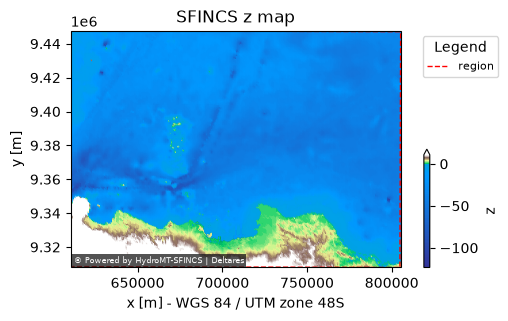

In [7]:
# [JAKARTA] We combine the elevation datasets in this order: the 2026 reclamation and harbour layer, DeltaDTM + seawalls (land, m EGM2008),
# GEBCO converted to EGM2008, and GEBCO 2026 (m MSL) for the remaining gaps. The first dataset has priority where it has data.
# NOTE: unlike the example, no "zmin" is set for the land dataset: about 9% of the North Jakarta land is below MSL (land subsidence)
# and would otherwise be replaced by GEBCO. DeltaDTM has no data over the sea, so GEBCO is still used there.
elevation_list = [
    {"elevation": "batimetri_reklamasi_2026"},  # [JAKARTA] reklamasi PIK/Pulau C-D, kolam dan alur Tanjung Priok 2026
    {"elevation": "dtm_jakarta_notanggul"},
    {"elevation": "bathy_gebco_egm08"},
    {"elevation": "gebco2026_luas", "offset": MSL},
]

# Add depth information to modelgrid based on these chosen datasets
sf.quadtree_elevation.create(elevation_list=elevation_list, buffer_cells=1)

# Make a plot of the merged topobathy
_ = sf.plot_basemap(
    variable="z", plot_region=True, plot_bounds=False, bmap="sat", zoomlevel=9  # [JAKARTA]
)

### 4. Make mask of active and inactive quadtree cells:

The next step of building a SFINCS model is to create a mask. First we generate a mask of active (msk=1) and inactive cells (msk=0), determining in which cells of your computational grid water levels will be computed.

For more info about the msk-file, [click here](https://sfincs.readthedocs.io/en/latest/input.html#mask-file). 

2026-11-27 09:10:18,043 - hydromt.hydromt_sfincs.components.quadtree.quadtree_mask - quadtree_mask - INFO - Building mask ...
2026-11-27 09:10:18,044 - hydromt.hydromt_sfincs.components.quadtree.quadtree_mask - quadtree_mask - INFO - Build new mask for: sfincs ...
2026-11-27 09:10:18,053 - hydromt.data_catalog.data_catalog - data_catalog - WARNING - overwriting data source 'domain_luas.geojson' with provider user and version _UNSPECIFIED_.
2026-11-27 09:10:18,054 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading domain_luas.geojson GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\domain_luas.geojson
2026-11-27 09:10:19,194 - hydromt.model.components.mesh - mesh - WARNING - Replacing mesh parameter: mask


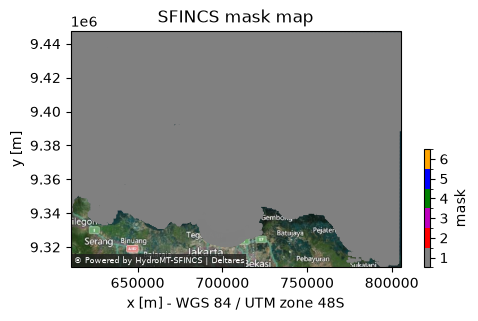

In [8]:
# [JAKARTA] Active cells from the region polygon instead of a minimum elevation (zmin=-5 in the example):
# the deep part of the bay must stay active for the tide to propagate to the coast.
sf.quadtree_mask.create_active(include_polygon=region["geom"])

# # Make a plot of the mask file
_ = sf.plot_basemap(
    variable="mask", plot_region=False, plot_bounds=False, bmap="sat", zoomlevel=9  # [JAKARTA]
)

<div style="padding: 14px 18px; border-left: 4px solid #d99000; background: #fff7e6; border-radius: 6px; margin: 12px 1em 12px 0; width: calc(100% - 1em); box-sizing: border-box; color: #111111; ">
  <strong><span style="font-size: 1.15em; margin-right: 4px;">&#9888;&#65039;</span> Note: Mask cleanup</strong>
  <ul style="margin: 8px 0 0;"><li>For quadtree models, the <code>fill_area</code>  and <code>drop_area</code> arguments are not available
</div>

### 5. Update mask with water level boundary cells - including use of polygons:

In SFINCS you can specify cells where you want to force offshore water levels (mask=2). To determine these cells, there are again multiple criteria to use, such as elevation or user-defined-polygons.

2026-11-27 09:10:28,167 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading batas_terbuka_luas.geojson GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\batas_terbuka_luas.geojson
2026-11-27 09:10:29,152 - hydromt.model.components.mesh - mesh - WARNING - Replacing mesh parameter: mask


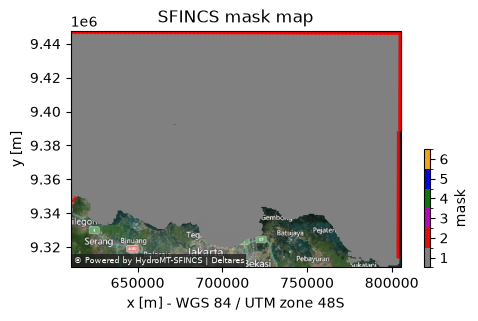

In [9]:
# Here we add water level cells along the offshore boundary, for cells up to an elevation of MSL - 3 m  # [JAKARTA]
sf.quadtree_mask.create_boundary(
    btype="waterlevel",
    zmax=MSL - 3.0,  # [JAKARTA]
    include_polygon="../data/domain/batas_terbuka_luas.geojson",  # [JAKARTA] only the west, north and east side
    reset_bounds=True,
)
# Make a plot of the mask file
fig, ax = sf.plot_basemap(
    variable="mask", plot_region=False, plot_bounds=False, bmap="sat", zoomlevel=9  # [JAKARTA]
)

<div style="padding: 14px 18px; border-left: 4px solid #187b8f; background: #eaf6f8; border-radius: 6px; margin: 12px 1em 12px 0; width: calc(100% - 1em); box-sizing: border-box; color: #111111; ">
  <strong><span style="font-size: 1.15em; margin-right: 4px;">&#128161;</span> Note: Boundary mask</strong>
  <ul style="margin: 8px 0 0;"><li>As shown in the plot, msk=2 values (red line) have been added along the offshore boundary.</li></ul><p style="margin: 8px 0 0;"><code>reset_bounds=True</code> means you start without existing boundary cells of that type. With <code>reset_bounds=False</code> (the default), you build on existing boundary cells, if available.</p>
</div>

### 6. Cut inactive cells from the quadtree grid

After creating the mask and boundary cells, remove inactive cells from the mesh before continuing with model preprocessing. The unstructured nature of the quadtree grids allows for removing unnecessary cells, making the pre-processing and running more efficient.



In [10]:
sf.quadtree_grid.cut_inactive_cells()

Removing inactive cells ...
Finding neighbors ...
Time elapsed : 0.035927772521972656 s
Setting neighbors left and below ...
Time elapsed : 0.28277134895324707 s
Getting uv points ...
Time elapsed : 0.22823286056518555 s
Making XUGrid ...
Got rid of duplicates in 0.8322 seconds
Made XUGrid in 0.0048 seconds


### 7. Add spatially varying roughness data:

Next to the elevation, the roughness is also an important input dataset for the SFINCS model. Typically, the mannings' n roughness coefficients are derived based on landuse/landcover data and a conversion table.

2026-11-27 09:10:40,229 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading esa_worldcover RasterDataset data from F:\asemelehoy\skema_terbaik\data\esa_worldcover\esa_worldcover.vrt
2026-11-27 09:10:40,259 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading esa_worldcover_mapping DataFrame data from F:\asemelehoy\skema_terbaik\data\esa_worldcover\esa_worldcover_mapping.csv
2026-11-27 09:11:00,334 - hydromt.hydromt_sfincs.components.quadtree.quadtree_roughness - quadtree_roughness - INFO - Filled 50773 remaining cells in manning with depth-based roughness.


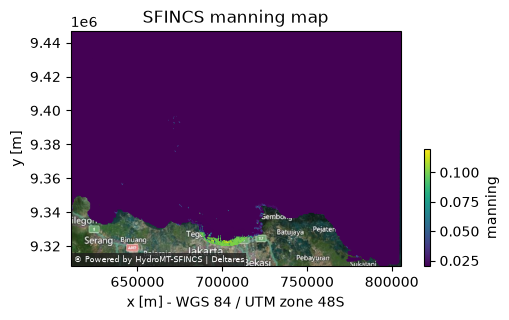

In [11]:
# Some reclass tables are available in the hydromt_sfincs DATADIR
# [JAKARTA] the same table (esa_worldcover_mapping.csv) is in our data catalog, so the Manning values can be checked and edited there
reclass_table = "esa_worldcover_mapping"  # [JAKARTA]

# use ESA WorldCover land cover to derive the manning roughness file  # [JAKARTA]
roughness_list = [{"lulc": "esa_worldcover", "reclass_table": reclass_table}]  # [JAKARTA]

sf.quadtree_roughness.create(
    roughness_list=roughness_list,
    manning_land=0.04,
    manning_sea=0.02,
    rgh_lev_land=MSL,  # [JAKARTA] the minimum elevation of the land (m EGM2008)
)
_ = sf.plot_basemap(variable="manning", plot_bounds=False, bmap="sat", zoomlevel=9)  # [JAKARTA]

### 8. Make quadtree subgrid-derived tables:

Subgrid derived tables are used to better capture the elevation and roughness of your domain, to either improve your results, or to allow you to run on a courser grid resolution (means faster simulation). For more info about subgrid tables, [click here](https://sfincs.readthedocs.io/en/latest/developments.html#recent-advancements-in-accuracy-subgrid-mode). 

You as user can specify multiple settings about how the subgrid derived tables should be made.

Every single grid cell of the flux grid of the size inp.dx by inp.dy is defined into subgrid pixels (default nr_subgrid_pixels = 20).
For every subgrid pixel the topobathy data is loaded, ideally this consists of high-resolution DEM datasets that you specify as user.

[JAKARTA] In this model the finest cells are 25 m (level 5) and 50 m (level 4). With nr_subgrid_pixels = 4 the subpixels are about 6 m and 12.5 m, already finer than the 30 m DeltaDTM, so we use 4.



For the subgrid tables, we again provide the elevation datasets, and roughness datasets. Additonally, we can provide river datasets that are used to burn in rivers into the elevation and roughness maps. 

In [12]:
# Repeat elevation and roughness sets for clarity
elevation_list = [
    {"elevation": "batimetri_reklamasi_2026"},  # [JAKARTA] reklamasi PIK/Pulau C-D, kolam dan alur Tanjung Priok 2026
    {"elevation": "dtm_jakarta_notanggul"},
    {"elevation": "bathy_gebco_egm08"},
    {"elevation": "gebco2026_luas", "offset": MSL},
]

# Roughness sets
roughness_list = [{"lulc": "esa_worldcover", "reclass_table": reclass_table}]  # [JAKARTA]

sf.quadtree_subgrid.create(
    elevation_list=elevation_list,
    roughness_list=roughness_list,
    nr_subgrid_pixels=4,  # [JAKARTA]
    write_dep_tif=True,
    write_man_tif=True,
)

# NOTE: we turned on that the merged topobathy of the different (high-res) datasets is written to a geotiff

2026-11-27 09:11:09,085 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading batimetri_reklamasi_2026 RasterDataset data from F:\asemelehoy\skema_terbaik\data\batimetri_reklamasi_2026\batimetri_reklamasi_2026.vrt
2026-11-27 09:11:09,277 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading dtm_jakarta_notanggul RasterDataset data from F:\asemelehoy\skema_terbaik\data\dtm_jakarta_notanggul\dtm_jakarta_notanggul.vrt
2026-11-27 09:11:09,469 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading bathy_gebco_egm08 RasterDataset data from F:\asemelehoy\skema_terbaik\data\bathy_gebco_egm08\bathy_gebco_egm08.vrt
2026-11-27 09:11:09,659 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading gebco2026_luas RasterDataset data from F:\asemelehoy\skema_terbaik\data\gebco2026_luas\gebco2026_luas.vrt
2026-11-27 09:11:09,858 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading batimetri_reklamasi_2026 R

The generated quadtree subgrid data are available through `sf.quadtree_subgrid.data` and are included when the model is written.


#### [JAKARTA] 8b. Add observation points

Not in the official example. These points (Muara Angke, the SKLP tide gauge cell, Tanjung Priok, etc.) are used to compare the model with the SKLP sensor. Cilincing lies outside the active cells and is dropped.

In [13]:
sf.observation_points.create(locations="../data/domain/titik_obs.geojson")  # [JAKARTA]

2026-11-27 09:12:39,337 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading titik_obs.geojson GeoDataFrame data from F:\asemelehoy\skema_terbaik\data\domain\titik_obs.geojson
2026-11-27 09:12:39,402 - hydromt.hydromt_sfincs.components.geometries.observation_points - observation_points - INFO - Adding new observation points to existing ones.


### 9. Add water level time-series as forcing:

There are many ways to add **water level boundary conditions** to the SFINCS model. We introduce one in the example below, check out the [WaterLevel](https://deltares.github.io/hydromt_sfincs/stable/_generated/hydromt_sfincs.components.forcing.SfincsWaterLevel.html) component for more options:

**🌐 Using a geodataset (presented here)**  
- The simplest option.  
- Contains time series of water levels at specific points.  
- Often generated by other models, such as the **GTSM model**.

[JAKARTA] Here: FES2022b tide + STOFS surge at the boundary points (`batas_fes_stofs` in the data catalog). The values are in m MSL, so an offset of +1.12 m converts them to m EGM2008. Wind and the other settings are added in [02_update_forcing](02_update_forcing.ipynb).

In [14]:
# Change period of model simulation time, specified in yyyymmdd HHMMSS, to match with the available water level data
sf.config.update(
    {
        "tref": datetime(2026, 10, 24),  # [JAKARTA]
        "tstart": datetime(2026, 10, 24),  # [JAKARTA]
        "tstop": datetime(2026, 10, 30, 23),  # [JAKARTA] ERA5 sampai 30 Okt 23:00
    }
)
# From geodataset
sf.water_level.create(geodataset="batas_fes_stofs", offset=MSL, buffer=12000)  # [JAKARTA] m MSL -> m EGM2008

2026-11-27 09:12:39,432 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 3 attributes in model config.
2026-11-27 09:12:39,500 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading batas_fes_stofs GeoDataset data from F:\asemelehoy\skema_terbaik\data\batas_fes_stofs\batas_fes_stofs.nc


### 10. Inspect the model and boundary conditions

To inspect the added boundary conditions, we can again use the plotting functionality of HydroMT-SFINCS. When the boundary conditions are related to boundary points (water levels and waves), these locations can be visualzied with `SfincsModel.plot_basemap(plot_geoms=True)`. Nonetheless, the actual timeseries of the boundary conditions can be visualized with `SfincsModel.plot_forcing()`.

(<Figure size 600x305.806 with 2 Axes>,
 <GeoAxes: title={'center': 'SFINCS z map'}, xlabel='x [m] - WGS 84 / UTM zone 48S', ylabel='y [m]'>)

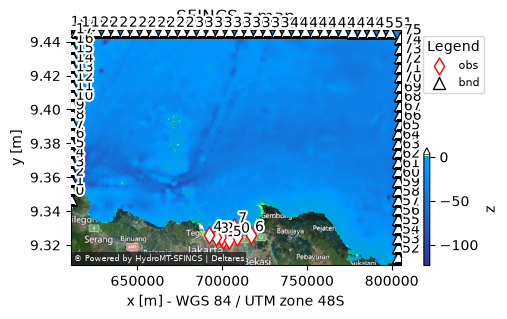

In [15]:
# plot basemap, in this case boundary points should be added (and plotted because of plot_geoms=True)
sf.plot_basemap(
    variable="z", plot_geoms=True, plot_bounds=False, bmap="sat", zoomlevel=9  # [JAKARTA]
)

And the boundary conditions timeseries:

(<Figure size 600x300 with 1 Axes>,
 [<Axes: title={'center': 'SFINCS waterlevel forcing (bzs)'}, ylabel='waterlevel\n[m+ref]'>])

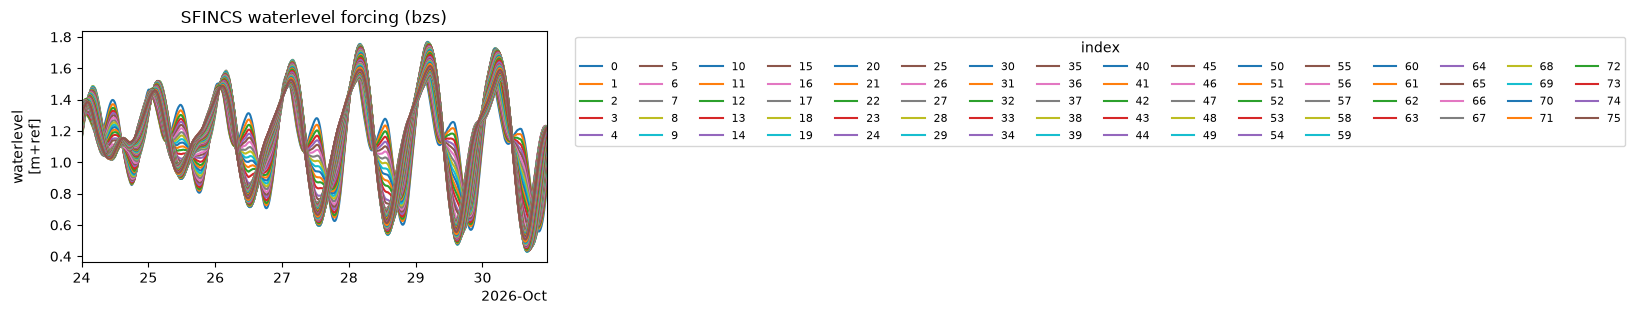

In [16]:
sf.plot_forcing()

### 11. Write the quadtree model input to disk

By now we have made all basic SFINCS spatial layers and added simple water level boundary conditions. We are ready to write the model to disk, and run the model. 

In [17]:
# write all model files to disk
sf.write()

2026-11-27 09:12:54,414 - hydromt.hydromt_sfincs.writers - writers - INFO - No changes detected; skipping write to F:\asemelehoy\skema_terbaik\model\jakarta_2026_tanpa_struktur\sfincs_netbndbzsbzifile.nc


[JAKARTA] Next, add wind, the simulation settings and the initial water level in the update notebook, then run the model:
- [Update Forcing](02_update_forcing.ipynb)
- [Run the model](03_run_model.ipynb)
- [Validate the water levels](04_validasi_muka_air.ipynb)